In [1]:
print("Colab is working!")


Colab is working!


In [2]:
%pip install -q ultralytics


In [3]:
import torch
import ultralytics

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics: 8.4.187
PyTorch: 2.11.0+cu130
GPU available: True


In [4]:
from google.colab import files

uploaded = files.upload()


Saving SmartCart-AI.v1i.yolov11.zip to SmartCart-AI.v1i.yolov11 (1).zip


In [5]:
import zipfile
import os
from pathlib import Path

zip_files = [f for f in uploaded.keys() if f.lower().endswith(".zip")]

assert zip_files, "Please upload your dataset ZIP file."

zip_path = zip_files[0]
extract_path = "/content/smartcart_dataset"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Dataset extracted to:", extract_path)

for root, dirs, files_list in os.walk(extract_path):
    level = root.replace(extract_path, "").count(os.sep)
    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")
        for f in files_list[:5]:
            print("  " * (level + 1) + f)

Dataset extracted to: /content/smartcart_dataset
smartcart_dataset/
  README.dataset.txt
  data.yaml
  README.roboflow.txt
  train/
    labels/
      bing_004_jpg.rf.2896409a73c2e448dd379e6ec2909a7e.txt
      bing_005_jpg.rf.e55caffe22bca37da6e5d808b3c5ba51.txt
      bing_001_jpg.rf.0a9c18cf8e7050a928c60fad6b5334dc.txt
      bing_004_jpg.rf.63ec14579b951fd1704206e57ddab3d9.txt
      bing_002_jpg.rf.889148b233f2a3d8719e62f738b10b89.txt
    images/
      bing_002_jpg.rf.565c15d6aa863781a6b1f8b90d73f84e.jpg
      bing_002_jpg.rf.d87fe261985f01a59b9f36ff173c41fb.jpg
      bing_005_jpg.rf.ab2ca3e6398d5067307b0dbaad8e3666.jpg
      bing_005_jpg.rf.4d40d52186707d72bbf301b9a603ec75.jpg
      bing_001_jpg.rf.df601c7b01866a6fba038e52f593f2b4.jpg
  valid/
    labels/
      bing_001_jpg.rf.47de2a2831a01082920e7d752ccbfc84.txt
      bing_003_jpg.rf.70f0acd44d48007a14d9d5c85e776656.txt
      bing_005_jpg.rf.c0721d7e8c8bdaec7357c235c6c2ca26.txt
      bing_002_jpg.rf.2b8a45a2f4f4f5b78abd26f7d91ff4a9.t

In [6]:
from pathlib import Path

yaml_files = list(Path("/content/smartcart_dataset").rglob("data.yaml"))

for p in yaml_files:
    print(p)


/content/smartcart_dataset/data.yaml


In [7]:
from pathlib import Path
from ultralytics import YOLO

yaml_files = list(Path("/content/smartcart_dataset").rglob("data.yaml"))
assert yaml_files, "data.yaml not found. Check your ZIP structure."

data_yaml = str(yaml_files[0])
print("Using dataset:", data_yaml)

model = YOLO("yolo11n.pt")

results = model.train(
    data=data_yaml,
    epochs=50,
    imgsz=640,
    batch=16,
    device=0 if __import__("torch").cuda.is_available() else "cpu",
    project="/content/SmartCart_AI",
    name="yolo11n_grocery",
    patience=10
)

Using dataset: /content/smartcart_dataset/data.yaml
Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/smartcart_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=

In [8]:
from google.colab import files

best_model = "/content/SmartCart_AI/yolo11n_grocery/weights/best.pt"
assert Path(best_model).exists(), "Training did not produce best.pt yet."

files.download(best_model)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
from google.colab import files

uploaded = files.upload()

Saving best.pt to best.pt


In [10]:
from ultralytics import YOLO

model = YOLO("/content/best.pt")

print("Model loaded successfully!")
print("Grocery classes:", model.names)

Model loaded successfully!
Grocery classes: {0: 'Amul-Butter', 1: 'Amul-masti', 2: 'Apple', 3: 'Banana', 4: 'Bisleri-water', 5: 'Britannaia chaeese spreadz', 6: 'Britannaia cheese garlic', 7: 'Britannaia fruit cake', 8: 'Britannaia fruitBread', 9: 'Britannaia whole wheatBread', 10: 'Britannaia-Sandwich-Bread', 11: 'Britannia-', 12: 'back pepper', 13: 'black pepper', 14: 'britannia gobbles egg less fruit cake', 15: 'broccoli', 16: 'cabbage', 17: 'carrot', 18: 'cocaco', 19: 'doughunut', 20: 'green apple', 21: 'kurkure', 22: 'lays', 23: 'light', 24: 'maggi', 25: 'milk mushroom', 26: 'onion', 27: 'onion stem', 28: 'orange', 29: 'parle-G', 30: 'pepsi', 31: 'potato', 32: 'sprite', 33: 'tomato'}


In [11]:
from google.colab import files

uploaded = files.upload()
image_path = next(iter(uploaded.keys()))

results = model.predict(
    source=image_path,
    conf=0.40,
    save=True
)

for result in results:
    for box in result.boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        print(
            model.names[class_id],
            f"{confidence:.2%}"
        )

Saving bing_002.jpg to bing_002.jpg

image 1/1 /content/bing_002.jpg: 448x640 (no detections), 9.3ms
Speed: 2.1ms preprocess, 9.3ms inference, 0.7ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/detect/predict


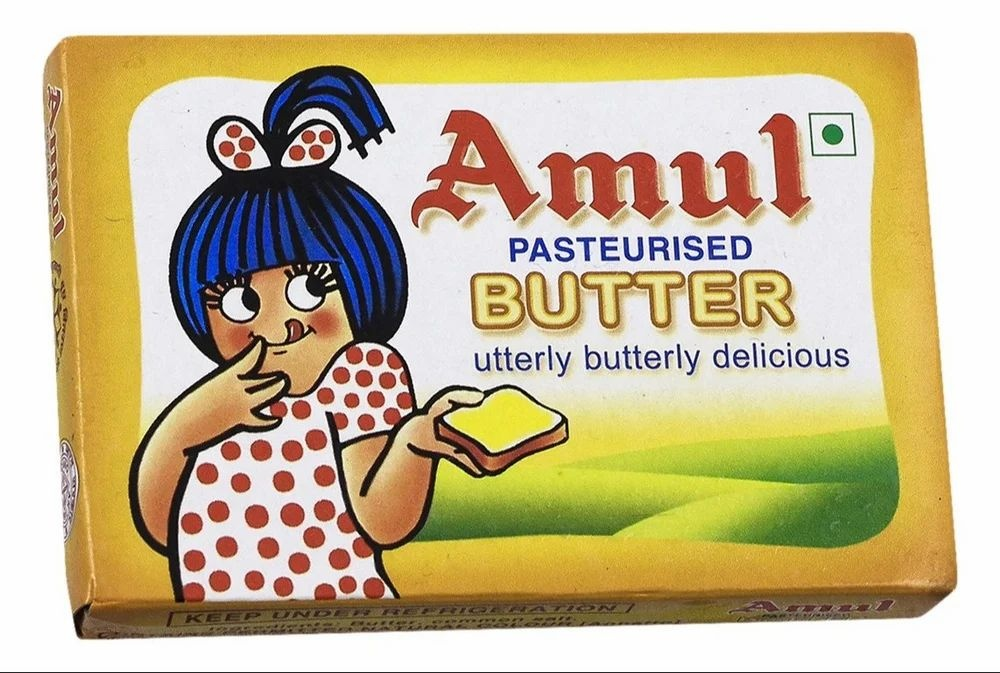

In [12]:
from IPython.display import display, Image
from pathlib import Path

output_dir = Path(results[0].save_dir)
images = list(output_dir.glob("*"))

if images:
    display(Image(filename=str(images[0])))